# INGV — Estimation du temps avant éruption à partir de signaux sismiques

**Objectif du projet :** étudier la prédiction de `time_to_eruption` à partir de dix capteurs sismiques. Les signaux sont transformés en **143 caractéristiques**, puis exploités par **XGBoost** et **LightGBM**. Les hyperparamètres sont sélectionnés par validation croisée sur la **MAE**, avec comparaison à une baseline médiane et évaluation sur un **holdout de 20 %**.

Ce notebook est consacré à **l'analyse prédictive et à l'évaluation scientifique**. Le holdout est constitué uniquement à partir des observations étiquetées : il sert uniquement à mesurer la qualité des prédictions sur des segments étiquetés non utilisés lors de l’apprentissage.

**Lecture des résultats :** les sorties conservées proviennent de la dernière exécution du notebook fourni ; relancer les cellules sur votre ordinateur pour les actualiser.

**Précaution :** le découpage aléatoire ne garantit pas l'indépendance entre épisodes volcaniques. Le modèle illustre une démarche de Data Science et **n'est pas un dispositif opérationnel d'alerte ou d'évacuation**.

## Ce que nous calculons exactement

Par **capteur** (10 capteurs), on extrait **14 variables** :

| Famille | Caractéristiques (suffixes des colonnes) | Nombre / capteur |
|---|---|---:|
| Statistiques | `mean`, `std`, `rms`, `mad`, `kurtosis`, `abs_q95` | 6 |
| Temporel | `window1_rms`, `window2_rms`, `window3_rms`, `window4_rms`, `autocorr_lag100` | 5 |
| Fréquentiel | `spectral_centroid`, `band_low` | 2 |
| Qualité | `missing_ratio` | 1 |

Trois variables **globales** complètent le tout : `sensor_count_valid`, `rms_across_sensors_mean`, `rms_across_sensors_std`.

**Total :** `10 × (6 + 5 + 2 + 1) + 3 = 143` colonnes candidates, même lorsqu'un capteur manque complètement (les valeurs non calculables restent `NaN`).

Quelques définitions :

- **RMS** : $\sqrt{\mathrm{mean}(x^2)}$ (niveau quadratique d'amplitude) ; **MAD** : $\mathrm{median}(|x-\mathrm{median}(x)|)$ (dispersion robuste).
- **Kurtosis** : $\mathrm{mean}(((x-\mu)/\sigma)^4)-3$, avec l'écart-type *population* $\sigma$ ; `NaN` si le signal est constant.
- **Fenêtres** : quatre quarts **chronologiques** du segment, RMS de chacun.
- **Autocorrélation 100** : corrélation de Pearson entre $x_t$ et $x_{t+100}$ sur les paires de mesures valides ; le retard est en **échantillons**.
- **Spectre** : densité spectrale de puissance estimée par **Welch**, après recentrage et interpolation si au moins 80 % des valeurs sont présentes ; `fs=1` signifie **cycles/échantillon**, **pas hertz physiques**. `band_low` est la proportion de puissance pour $0 \le f < 10\%$ de Nyquist ; `spectral_centroid` est la moyenne pondérée des fréquences par la puissance.
- **Qualité** : proportion de valeurs manquantes pour chaque capteur.

Ces caractéristiques sont des **hypothèses prédictives**, pas des marqueurs volcaniques validés. Les métriques d'**évaluation** (MAE, RMSE et R²) sont distinctes de ces caractéristiques.

## 1 · Préparation du notebook

### 1.1 · Importer les bibliothèques

In [1]:
import os
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
from tqdm.auto import tqdm

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, RandomizedSearchCV, train_test_split, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer
import lightgbm as lgb
import xgboost as xgb
import joblib

### 1.2 · Définir les dossiers du projet

Indiquer le dossier local contenant `train.csv` et les fichiers de signaux du dossier `train` (éventuellement `train/train` après extraction). Les sorties de l'analyse sont enregistrées séparément dans `OUT_DIR`.

In [2]:
SEED = 42

# Dossier local des données d'étude : adapter ce chemin si nécessaire.
DATA_DIR = Path(r'C:\Users\Alexis\Desktop\Projet INGV').expanduser().resolve()

OUT_DIR = Path(os.getenv('INGV_OUTPUT_DIR', 'outputs_INGV_143')).expanduser().resolve()
CACHE_DIR = OUT_DIR / 'cache'
OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Certains téléchargements placent les segments dans train/train.
TRAIN_DIR = DATA_DIR / 'train' / 'train' if (DATA_DIR / 'train' / 'train').is_dir() else DATA_DIR / 'train'

print('Dossier des données :', DATA_DIR)
print('Segments sismiques :', TRAIN_DIR)
print('Résultats du projet :', OUT_DIR)

Dossier des données : C:\Users\Alexis\Desktop\Projet INGV
Segments sismiques : C:\Users\Alexis\Desktop\Projet INGV\train\train
Résultats du projet : C:\Users\Alexis\Desktop\Projet INGV\outputs_INGV_143


### 1.3 · Paramètres généraux

`N_ITER_SEARCH` fixe le nombre de configurations testées **pour chacun des deux modèles** ; la validation croisée utilise `N_SPLITS` folds. Le holdout n'intervient pas dans le choix des hyperparamètres.

In [3]:
FEATURE_VERSION = "v143_1"
FORCE_REEXTRACT = False
CHECKPOINT_EVERY = 100
HOLDOUT_SIZE = 0.20
N_SPLITS = 5
N_ITER_SEARCH = 10
MODEL_THREADS = 4

print('Configuration du projet INGV')
print('----------------------------')
print('Caractéristiques : 143')
print(f'Holdout de validation : {HOLDOUT_SIZE:.0%}')
print(f'Validation croisée : {N_SPLITS} folds')
print(f'Recherche XGBoost / LightGBM : {N_ITER_SEARCH} essais par modèle')
print(f'Threads CPU : {MODEL_THREADS}')
print(f'Réutilisation du cache : {not FORCE_REEXTRACT}')

Configuration du projet INGV
----------------------------
Caractéristiques : 143
Holdout de validation : 20%
Validation croisée : 5 folds
Recherche XGBoost / LightGBM : 10 essais par modèle
Threads CPU : 4
Réutilisation du cache : True


### 1.4 · Définir les 143 colonnes explicatives
On vérifie leur nom et leur nombre avant toute lecture des signaux.

In [4]:
SENSORS = [f'sensor_{j}' for j in range(1, 11)]
STATS = ('mean', 'std', 'rms', 'mad', 'kurtosis', 'abs_q95')
TEMPORAL = ('window1_rms', 'window2_rms', 'window3_rms', 'window4_rms', 'autocorr_lag100')
FREQUENCY = ('spectral_centroid', 'band_low')
QUALITY = ('missing_ratio',)
GLOBAL = ('sensor_count_valid', 'rms_across_sensors_mean', 'rms_across_sensors_std')
FEATURE_COLUMNS = [f'{sensor}_{suffix}' for sensor in SENSORS
                   for suffix in STATS + TEMPORAL + FREQUENCY + QUALITY] + list(GLOBAL)
assert len(FEATURE_COLUMNS) == 143 and len(set(FEATURE_COLUMNS)) == 143
print('Caractéristiques :', len(FEATURE_COLUMNS))

Caractéristiques : 143


## 2 · Vérifier les données étiquetées avant les calculs

### 2.1 · Vérification des métadonnées des segments

In [5]:
def check_metadata(train_meta):
    required = {'segment_id', 'time_to_eruption'}
    missing_columns = required - set(train_meta.columns)
    if missing_columns:
        raise ValueError(f'Colonnes manquantes dans train.csv : {sorted(missing_columns)}')

    ids = train_meta['segment_id']
    if ids.isna().any() or ids.duplicated().any():
        raise ValueError('Les identifiants des segments sont nuls ou dupliqués')

    target = pd.to_numeric(train_meta['time_to_eruption'], errors='raise').to_numpy(dtype=float)
    if not np.isfinite(target).all() or (target < 0).any():
        raise ValueError('La variable time_to_eruption doit être numérique, finie et positive ou nulle')

### 2.2 · Charger les métadonnées `train.csv`

Les observations étiquetées suffisent pour entraîner les modèles, créer un jeu de validation et analyser les erreurs. `segment_id` est lu comme du texte afin d'assurer une jointure fiable avec les caractéristiques extraites.

In [6]:
metadata_path = DATA_DIR / 'train.csv'
if not metadata_path.is_file():
    raise FileNotFoundError(f'Métadonnées introuvables : {metadata_path}')
if not TRAIN_DIR.is_dir():
    raise FileNotFoundError(f'Dossier des signaux introuvable : {TRAIN_DIR}')

train_meta = pd.read_csv(metadata_path, dtype={'segment_id': 'string'})
check_metadata(train_meta)

print('Métadonnées chargées :', len(train_meta), 'segments étiquetés')
display(train_meta.head(3))

Métadonnées chargées : 4431 segments étiquetés


,segment_id,time_to_eruption
0,1136037770,12262005
1,1969647810,32739612
2,1895879680,14965999


### 2.3 · Contrôler la présence des fichiers sismiques

Un fichier CSV doit correspondre à chaque identifiant répertorié dans `train.csv`.

In [7]:
missing_train = [sid for sid in train_meta['segment_id']
                 if not (TRAIN_DIR / f'{sid}.csv').is_file()]
print('Segments sans fichier :', len(missing_train), '| Exemples :', missing_train[:3])
if missing_train:
    raise FileNotFoundError('Des fichiers de signaux sont absents : vérifier TRAIN_DIR.')
print('Contrôle des fichiers terminé')

Segments sans fichier : 0 | Exemples : []
Contrôle des fichiers terminé


## 3 · Calculer les caractéristiques des signaux

### 3.1 · Autocorrélation au retard 100

In [8]:
def autocorr_at_lag(values, lag=100, min_pairs=10):
    if len(values) <= lag:
        return np.nan
    left, right = values[:-lag], values[lag:]
    ok = np.isfinite(left) & np.isfinite(right)
    if ok.sum() < min_pairs:
        return np.nan
    a, b = left[ok].astype(np.float64), right[ok].astype(np.float64)
    sa, sb = a.std(), b.std()
    if sa < 1e-12 or sb < 1e-12:
        return np.nan
    return float(np.mean(((a - a.mean()) / sa) * ((b - b.mean()) / sb)))

### 3.2 · Statistiques spectrales via Welch
Avec `fs=1`, l’unité est le cycle par échantillon, pas le hertz.

In [9]:
def spectrum_features(values):
    valid = np.isfinite(values)
    n = len(values)
    if valid.sum() < 32 or valid.mean() < 0.80:
        return np.nan, np.nan
    # Interpolation linéaire uniquement pour calculer le spectre, après contrôle des valeurs présentes.
    filled = np.interp(np.arange(n), np.flatnonzero(valid), values[valid]).astype(np.float64)
    filled -= filled.mean()
    freqs, power = welch(filled, fs=1.0, nperseg=min(1024, n))
    power = np.maximum(power, 0)
    total = float(power.sum())
    if total <= 1e-12:
        return np.nan, np.nan
    weights = power / total
    centroid = float(np.sum(freqs * weights))
    low_fraction = float(np.sum(weights[freqs < 0.05]))  # 10 % de Nyquist (fs=1)
    return centroid, low_fraction

### 3.3 · Calculer les **14 variables d’un capteur**
Une fonction correspond à un seul capteur : si une statistique est incorrecte, le problème est localisé ici.

In [10]:
def features_one_sensor(whole, sensor):
    prefix = f'{sensor}_'
    valid = whole[np.isfinite(whole)].astype(np.float64)
    output = {prefix + 'missing_ratio': float(1 - len(valid) / len(whole))}

    if len(valid) == 0:
        output.update({prefix + name: np.nan for name in STATS + TEMPORAL + FREQUENCY})
        return output, np.nan

    mean = float(valid.mean())
    rms = float(np.sqrt(np.mean(valid ** 2)))
    med = float(np.median(valid))
    std_population = float(valid.std(ddof=0))
    output.update({
        prefix + 'mean': mean,
        prefix + 'std': float(valid.std(ddof=1)) if len(valid) >= 2 else np.nan,
        prefix + 'rms': rms,
        prefix + 'mad': float(np.median(np.abs(valid - med))),
        prefix + 'abs_q95': float(np.percentile(np.abs(valid), 95)),
        prefix + 'kurtosis': float(np.mean(((valid - mean) / std_population) ** 4) - 3.0)
                              if std_population > 1e-12 else np.nan,
    })
    for k, window in enumerate(np.array_split(whole, 4), start=1):
        clean = window[np.isfinite(window)].astype(np.float64)
        output[prefix + f'window{k}_rms'] = float(np.sqrt(np.mean(clean ** 2))) if len(clean) else np.nan
    output[prefix + 'autocorr_lag100'] = autocorr_at_lag(whole, lag=100)
    centroid, low_fraction = spectrum_features(whole)
    output[prefix + 'spectral_centroid'] = centroid
    output[prefix + 'band_low'] = low_fraction
    return output, rms

### 3.4 · Regrouper les capteurs en **une ligne de 143 variables**

In [11]:
def segment_features_from_frame(raw):
    if len(raw) < 10:
        raise ValueError('Segment trop court : moins de 10 mesures')
    raw = raw.reindex(columns=SENSORS).apply(pd.to_numeric, errors='coerce')
    matrix = raw.to_numpy(dtype=np.float32, copy=True)
    matrix[~np.isfinite(matrix)] = np.nan

    features, rms_per_sensor = {}, []
    for j, sensor in enumerate(SENSORS):
        sensor_features, rms = features_one_sensor(matrix[:, j], sensor)
        features.update(sensor_features)
        rms_per_sensor.append(rms)

    good_rms = np.asarray(rms_per_sensor, dtype=float)
    good_rms = good_rms[np.isfinite(good_rms)]
    features['sensor_count_valid'] = int(len(good_rms))
    features['rms_across_sensors_mean'] = float(good_rms.mean()) if len(good_rms) else np.nan
    features['rms_across_sensors_std'] = float(good_rms.std(ddof=0)) if len(good_rms) else np.nan
    if set(features) != set(FEATURE_COLUMNS):
        raise RuntimeError('Colonnes calculées différentes des 143 colonnes attendues')
    return {name: features[name] for name in FEATURE_COLUMNS}

### 3.5 · Lecture d’un fichier CSV sismique

In [12]:
def extract_file(path):
    if not path.is_file():
        raise FileNotFoundError(f'Fichier sismique absent : {path}')
    try:
        raw = pd.read_csv(path, dtype='float32')
    except Exception as exc:
        raise RuntimeError(f'Lecture CSV impossible : {path}') from exc
    return segment_features_from_frame(raw)

### 3.6 · Test unitaire : signal normal

In [13]:
demo = pd.DataFrame({s: (30 * np.sin(np.arange(240) / 12 + i)).astype(float)
                     for i, s in enumerate(SENSORS)})
features_ok = segment_features_from_frame(demo)
assert list(features_ok) == FEATURE_COLUMNS and len(features_ok) == 143
assert np.isfinite(features_ok['sensor_1_rms'])
print('Test signal normal OK')

Test signal normal OK


### 3.7 · Tests unitaires : capteur absent et signal constant

In [14]:
demo_missing = demo.copy()
demo_missing['sensor_2'] = np.nan
features_missing = segment_features_from_frame(demo_missing)
assert features_missing['sensor_2_missing_ratio'] == 1.0
assert np.isnan(features_missing['sensor_2_rms'])
assert features_missing['sensor_count_valid'] == 9

demo_constant = pd.DataFrame({s: np.zeros(240) for s in SENSORS})
features_constant = segment_features_from_frame(demo_constant)
assert np.isnan(features_constant['sensor_1_kurtosis'])
assert np.isnan(features_constant['sensor_1_spectral_centroid'])
print('Tests données manquantes et constantes OK')

Tests données manquantes et constantes OK


## 4 · Extraire les caractéristiques et réutiliser le cache

La première exécution parcourt les segments étiquetés. Les exécutions suivantes réutilisent le cache tant que les données et `FEATURE_VERSION` restent inchangées.

### 4.1 · Définir les fichiers de cache

In [15]:
def cache_files(meta, folder, label):
    ids = meta['segment_id'].astype('string').tolist()
    digest = hashlib.sha256((str(folder.resolve()) + '|' + '|'.join(ids)).encode()).hexdigest()[:12]
    prefix = CACHE_DIR / f'{label}_{FEATURE_VERSION}_{digest}'
    return Path(str(prefix) + '.csv.gz'), Path(str(prefix) + '.partial.pkl')

### 4.2 · Vérifier la structure du cache

In [16]:
def check_feature_table(table, ids):
    if table['segment_id'].isna().any() or table['segment_id'].duplicated().any():
        raise ValueError('IDs du cache manquants ou dupliqués')
    if len(table) != len(ids) or set(table['segment_id'].tolist()) != set(ids):
        raise ValueError('Segments du cache incohérents avec les métadonnées')
    if set(table.columns) != {'segment_id', *FEATURE_COLUMNS}:
        raise ValueError('Le cache ne contient pas les 143 bonnes caractéristiques')

### 4.3 · Lire le cache existant ou reprendre une extraction interrompue

In [17]:
def load_or_extract(meta, folder, label):
    ids = meta['segment_id'].astype('string').tolist()
    full, partial = cache_files(meta, folder, label)

    if FORCE_REEXTRACT:
        full.unlink(missing_ok=True)
        partial.unlink(missing_ok=True)

    if full.exists():
        table = pd.read_csv(full, dtype={'segment_id': 'string'})
        check_feature_table(table, ids)
        print(f'{label} : cache complet réutilisé ({len(table)} segments)')
        return table.set_index('segment_id').loc[ids].reset_index()[['segment_id', *FEATURE_COLUMNS]]

    if partial.exists():
        table = pd.read_pickle(partial)
        if table['segment_id'].duplicated().any() or not set(table['segment_id']).issubset(set(ids)):
            raise ValueError('Cache partiel incohérent')
        if set(table.columns) != {'segment_id', *FEATURE_COLUMNS}:
            raise ValueError('Colonnes du cache partiel incohérentes')
        records = table.to_dict('records')
    else:
        records = []

    return continue_extraction(records, ids, folder, label, full, partial)

### 4.4 · Traiter les segments manquants par lots et sauvegarder
En cas d’erreur sur un fichier, le message indiquera son identifiant ; les lots déjà sauvegardés sont conservés.

In [18]:
def continue_extraction(records, ids, folder, label, full, partial):
    seen = {str(r['segment_id']) for r in records}
    pending = [sid for sid in ids if sid not in seen]
    print(f'{label} : {len(seen)} en cache, {len(pending)} à traiter')

    for start in tqdm(range(0, len(pending), CHECKPOINT_EVERY), desc=f'Extraction {label}'):
        for sid in pending[start:start + CHECKPOINT_EVERY]:
            try:
                records.append({'segment_id': str(sid), **extract_file(folder / f'{sid}.csv')})
            except Exception as exc:
                raise RuntimeError(f'Échec du segment {sid} ({label})') from exc
        temporary = Path(str(partial) + '.tmp')
        pd.DataFrame.from_records(records)[['segment_id', *FEATURE_COLUMNS]].to_pickle(temporary)
        temporary.replace(partial)

    table = pd.DataFrame.from_records(records, columns=['segment_id', *FEATURE_COLUMNS])
    if len(table):
        table['segment_id'] = table['segment_id'].astype('string')
    check_feature_table(table, ids)
    table = table.set_index('segment_id').loc[ids].reset_index()[['segment_id', *FEATURE_COLUMNS]]
    temporary = Path(str(full) + '.tmp')
    table.to_csv(temporary, index=False, compression='gzip')
    temporary.replace(full)
    partial.unlink(missing_ok=True)
    print('Cache complet :', full)
    return table

### 4.5 · Extraire les caractéristiques des segments étiquetés

Le cache évite de recalculer les 143 variables à chaque nouvelle exécution du notebook.

In [19]:
train_features = load_or_extract(train_meta, TRAIN_DIR, 'train')
print('Train :', train_features.shape)
assert train_features.shape == (len(train_meta), 144)

train : cache complet réutilisé (4431 segments)
Train : (4431, 144)


## 5 · Préparer les données pour la modélisation

### 5.1 · Associer les caractéristiques et la cible par `segment_id`

La jointure s'effectue par identifiant, jamais par simple position de ligne. Les correspondances sont vérifiées avant de poursuivre.

In [20]:
# Harmoniser les identifiants et assurer une correspondance exacte.
train_meta['segment_id'] = train_meta['segment_id'].astype('string')
train_features['segment_id'] = train_features['segment_id'].astype('string')

train_table = train_meta.merge(
    train_features,
    on='segment_id',
    how='left',
    validate='one_to_one',
    sort=False,
    indicator=True,
)

if not (train_table['_merge'] == 'both').all():
    missing_ids = train_table.loc[train_table['_merge'] != 'both', 'segment_id'].tolist()
    raise ValueError(f'Segments sans caractéristiques : {missing_ids[:5]}')

train_table = train_table.drop(columns='_merge')
assert train_table['segment_id'].tolist() == train_meta['segment_id'].tolist()
print('Jointure validée :', len(train_table), 'segments étiquetés')

Jointure validée : 4431 segments étiquetés


### 5.2 · Construire les matrices X et y

`X` contient uniquement les 143 caractéristiques, tandis que `y` contient `time_to_eruption`. L'identifiant n'est pas utilisé pour prédire.

In [21]:
X = train_table[FEATURE_COLUMNS].astype('float32').replace([np.inf, -np.inf], np.nan)
y = train_table['time_to_eruption'].astype('float64').reset_index(drop=True)

assert X.shape == (len(train_meta), 143)
assert len(y) == len(X)
assert not X.columns.duplicated().any()
print('Caractéristiques X :', X.shape, '| Cible y :', y.shape)

Caractéristiques X : (4431, 143) | Cible y : (4431,)


### 5.3 · Séparer développement et validation finale
Attention : sans groupes d’épisodes volcaniques fiables, ce split aléatoire ne teste pas une généralisation temporelle.

In [22]:
idx_dev, idx_holdout = train_test_split(np.arange(len(X)), test_size=HOLDOUT_SIZE,
                                       shuffle=True, random_state=SEED)
X_dev, X_holdout = X.iloc[idx_dev], X.iloc[idx_holdout]
y_dev, y_holdout = y.iloc[idx_dev], y.iloc[idx_holdout]
assert set(idx_dev).isdisjoint(set(idx_holdout))
print('Développement :', len(X_dev), '| Holdout :', len(X_holdout))

Développement : 3544 | Holdout : 887


### 5.4 · Contrôler les valeurs manquantes des caractéristiques

Cette comparaison descriptive entre développement et holdout sert au contrôle de qualité ; elle ne modifie pas les modèles ni la sélection des hyperparamètres.

In [23]:
quality = pd.DataFrame({
    'missing_dev_pct': 100 * X_dev.isna().mean(),
    'missing_holdout_pct': 100 * X_holdout.isna().mean(),
    'std_dev': X_dev.std(),
})
quality.to_csv(OUT_DIR / 'feature_quality.csv', index_label='feature')
display(quality.sort_values('missing_dev_pct', ascending=False).head(10))

,missing_dev_pct,missing_holdout_pct,std_dev
sensor_2_spectral_centroid,19.441309,17.361894,0.014683
sensor_2_band_low,19.441309,17.361894,0.131200
sensor_2_abs_q95,19.272009,17.136415,3711.331299
sensor_2_window4_rms,19.272009,17.249154,1914.447876
sensor_2_window3_rms,19.272009,17.249154,1935.932373
sensor_2_window2_rms,19.272009,17.249154,1970.823364
sensor_2_window1_rms,19.272009,17.136415,2014.021729
sensor_2_kurtosis,19.272009,17.136415,26.576384
sensor_2_mad,19.272009,17.136415,1317.673584
sensor_2_rms,19.272009,17.136415,1938.205688


## 6 · Sélectionner les hyperparamètres **sur la validation croisée**, pas le holdout

### 6.1 · Métrique MAE et découpage à 5 folds

In [24]:
def clipped_mae(y_true, y_pred):
    predictions = np.maximum(np.asarray(y_pred, dtype=float), 0)
    return mean_absolute_error(y_true, predictions)

MAE_SCORER = make_scorer(clipped_mae, greater_is_better=False)
cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
print(f'Validation croisée : {N_SPLITS} folds, MAE minimisée')

Validation croisée : 5 folds, MAE minimisée


### 6.2 · Mesurer la baseline médiane

In [25]:
median = DummyRegressor(strategy='median')
y_oof_baseline = cross_val_predict(median, X_dev, y_dev, cv=cv, n_jobs=1)
cv_mae_baseline = clipped_mae(y_dev, y_oof_baseline)
print(f'MAE baseline CV : {cv_mae_baseline:,.0f}')

MAE baseline CV : 11,590,126


### 6.3 · Définir la recherche XGBoost

In [26]:
xgb_estimator = xgb.XGBRegressor(
    objective='reg:squarederror', tree_method='hist',
    n_jobs=MODEL_THREADS, random_state=SEED,
)
xgb_space = {
    'n_estimators': [200, 400, 650], 'max_depth': [2, 3, 4, 5],
    'learning_rate': [0.03, 0.06, 0.10], 'min_child_weight': [3, 8, 15],
    'subsample': [0.8, 1.0], 'colsample_bytree': [0.7, 1.0],
    'reg_lambda': [2, 10, 30],
}
print('XGBoost configuré')

XGBoost configuré


### 6.4 · Rechercher les hyperparamètres XGBoost

In [27]:
xgb_search = RandomizedSearchCV(
    estimator=xgb_estimator,
    param_distributions=xgb_space,
    n_iter=N_ITER_SEARCH,
    scoring=MAE_SCORER,
    cv=cv,
    refit=True,
    n_jobs=1,
    random_state=SEED,
    error_score='raise',
    verbose=1,
)
xgb_search.fit(X_dev, y_dev)
print('MAE CV XGBoost :', -xgb_search.best_score_)
print('Hyperparamètres XGBoost :', xgb_search.best_params_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
MAE CV XGBoost : 3384852.6363436803
Hyperparamètres XGBoost : {'subsample': 0.8, 'reg_lambda': 30, 'n_estimators': 650, 'min_child_weight': 15, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


### 6.5 — Optimisation de LightGBM

In [28]:
lgb_model = lgb.LGBMRegressor(
    objective="regression",
    random_state=SEED,
    n_jobs=MODEL_THREADS,
    verbosity=-1
)
lgb_params = {
    "n_estimators": [200, 400, 650],
    "max_depth": [3, 4, 5],
    "num_leaves": [7, 15, 31],
    "learning_rate": [0.03, 0.06, 0.10],
    "min_child_samples": [20, 40, 60],
    "colsample_bytree": [0.7, 1.0],
    "reg_lambda": [2, 10, 30]
}
print('LightGBM configuré')

LightGBM configuré


In [29]:
lgb_search = RandomizedSearchCV(
    estimator=lgb_model,
    param_distributions=lgb_params,
    n_iter=N_ITER_SEARCH,
    scoring=MAE_SCORER,
    cv=cv,
    n_jobs=1,
    random_state=SEED,
    refit=True,
    error_score="raise",
    verbose=1
)
lgb_search.fit(X_dev, y_dev)
print("Meilleure MAE LightGBM :",
      -lgb_search.best_score_)
print("Meilleurs hyperparamètres :")
print(lgb_search.best_params_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Meilleure MAE LightGBM : 3760727.940891652
Meilleurs hyperparamètres :
{'reg_lambda': 30, 'num_leaves': 15, 'n_estimators': 650, 'min_child_samples': 60, 'max_depth': 4, 'learning_rate': 0.06, 'colsample_bytree': 1.0}


### 6.6 — Comparaison des modèles

In [30]:
# Regrouper les modèles optimisés
searches = {
    "XGBoost": xgb_search,
    "LightGBM": lgb_search
}
# Résultats de validation croisée
results = [
    {
        "Modèle": "XGBoost",
        "MAE_CV": -xgb_search.best_score_,
        'Ecart_type_CV': xgb_search.cv_results_["std_test_score"][xgb_search.best_index_]
    },
    {
        "Modèle": "LightGBM",
        "MAE_CV": -lgb_search.best_score_,
        'Ecart_type_CV': lgb_search.cv_results_["std_test_score"][lgb_search.best_index_]
    }
]
# Construire le tableau
cv_results = pd.DataFrame(results)
# Classer selon la MAE
cv_results = cv_results.sort_values(
    "MAE_CV"
).reset_index(drop=True)
display(cv_results)
# Enregistrer les résultats
cv_results.to_csv(
    OUT_DIR / "model_comparison.csv",
    index=False
)

,Modèle,MAE_CV,Ecart_type_CV
0,XGBoost,3.384853e+06,64506.550635
1,LightGBM,3.760728e+06,98158.213441


### 6.7 — Sélection automatique du meilleur modèle

In [31]:
# Trouver le meilleur modèle en validation croisée
best_candidate = min(
    searches,
    key=lambda name: -searches[name].best_score_
)
best_cv_mae = -searches[best_candidate].best_score_

# Comparer à la baseline
if best_cv_mae < 0.995 * cv_mae_baseline:
    selected_name = best_candidate
    selected_template = searches[
        selected_name
    ].best_estimator_
else:
    selected_name = "Baseline médiane"
    selected_template = DummyRegressor(
        strategy="median"
    )
print("Modèle sélectionné :", selected_name)
print(f"Meilleure MAE CV : {best_cv_mae:.0f}")

Modèle sélectionné : XGBoost
Meilleure MAE CV : 3384853


## 7 — Évaluation du meilleur modèle

### 7.1 · Entraîner le modèle sur le développement

In [32]:
# Récupérer le modèle sélectionné
if selected_name == "Baseline médiane":
    chosen = DummyRegressor(strategy="median")
    chosen.fit(X_dev, y_dev)
else:
    # Déjà entraîné sur X_dev par RandomizedSearchCV
    chosen = searches[selected_name].best_estimator_

# Prédictions
pred_holdout = chosen.predict(X_holdout)

# Empêcher les temps négatifs
pred_holdout = np.maximum(pred_holdout, 0)

# Prédictions de la baseline
naive = DummyRegressor(strategy="median")
naive.fit(X_dev, y_dev)

pred_naive = naive.predict(X_holdout)

print("Modèle utilisé :", selected_name)
print("Nombre de prédictions :", len(pred_holdout))

Modèle utilisé : XGBoost
Nombre de prédictions : 887


### 7.2 · Calculer MAE, RMSE et R²

In [33]:
mae_model = mean_absolute_error(y_holdout, pred_holdout)
mae_naive = mean_absolute_error(y_holdout, pred_naive)
metrics = pd.DataFrame([{
    'modele': selected_name, 'holdout_n': len(y_holdout),
    'MAE': float(mae_model), 'MAE_baseline': float(mae_naive),
    'gain_MAE_vs_baseline_pct': float(100 * (1 - mae_model / mae_naive)) if mae_naive else np.nan,
    'RMSE': float(np.sqrt(mean_squared_error(y_holdout, pred_holdout))),
    'R2': float(r2_score(y_holdout, pred_holdout)),
}])
metrics.to_csv(OUT_DIR / 'holdout_metrics.csv', index=False)
display(metrics.T.rename(columns={0: 'Valeur'}))

,Valeur
modele,XGBoost
holdout_n,887
MAE,3140284.9652
MAE_baseline,11832397.410936
gain_MAE_vs_baseline_pct,73.460281
RMSE,4305978.121073
R2,0.899919


### 7.3 · Sauvegarder les prédictions individuelles

In [34]:
predictions = pd.DataFrame({
    'segment_id': train_meta.iloc[idx_holdout].segment_id.to_numpy(),
    'y_true': y_holdout.to_numpy(), 'y_pred': pred_holdout,
    'erreur_absolue': np.abs(y_holdout.to_numpy() - pred_holdout),
})
predictions.to_csv(OUT_DIR / 'holdout_predictions.csv', index=False)
print('Fichier :', OUT_DIR / 'holdout_predictions.csv')

Fichier : C:\Users\Alexis\Desktop\Projet INGV\outputs_INGV_143\holdout_predictions.csv


### 7.4 · Graphique : réel vs prédit

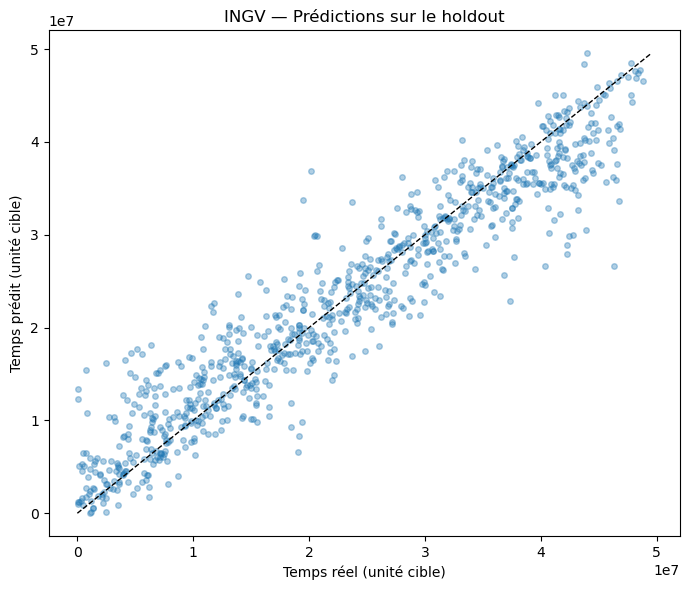

In [35]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_holdout, pred_holdout, alpha=0.35, s=16)
limit = max(float(np.max(y_holdout)), float(np.max(pred_holdout)))
ax.plot([0, limit], [0, limit], linestyle='--', linewidth=1, color='black')
ax.set(xlabel='Temps réel (unité cible)', ylabel='Temps prédit (unité cible)',
       title='INGV — Prédictions sur le holdout')
fig.tight_layout()
fig.savefig(OUT_DIR / 'predictions_holdout.png', dpi=150)
plt.show()

### 7.5 · Graphique : résidus du modèle

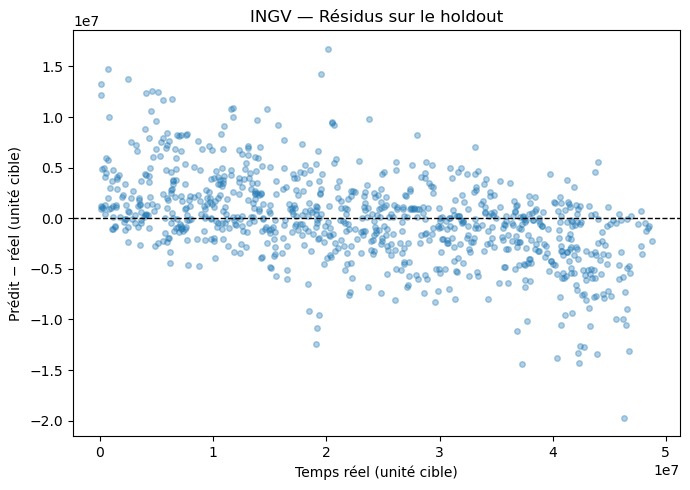

In [36]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_holdout, pred_holdout - y_holdout.to_numpy(), alpha=0.35, s=16)
ax.axhline(0, linestyle='--', linewidth=1, color='black')
ax.set(xlabel='Temps réel (unité cible)', ylabel='Prédit − réel (unité cible)',
       title='INGV — Résidus sur le holdout')
fig.tight_layout()
fig.savefig(OUT_DIR / 'residus_holdout.png', dpi=150)
plt.show()

### 7.6 · Erreur en fonction du temps réellement restant

In [37]:
# Tableau des prédictions
analyse = pd.DataFrame({
    "temps_reel": np.asarray(y_holdout),
    "temps_predit": np.asarray(pred_holdout)
})

# Erreur signée et erreur absolue
analyse["erreur"] = (
    analyse["temps_predit"] - analyse["temps_reel"]
)
analyse["erreur_absolue"] = analyse["erreur"].abs()

# Répartir les observations en quatre groupes
analyse["quartile"] = pd.qcut(
    analyse["temps_reel"],
    q=4,
    duplicates="drop"
)

# Résumer les résultats
bilan = analyse.groupby(
    "quartile",
    observed=True
).agg(
    nombre=("erreur", "size"),
    temps_reel_moyen=("temps_reel", "mean"),
    temps_predit_moyen=("temps_predit", "mean"),
    biais_moyen=("erreur", "mean"),
    MAE=("erreur_absolue", "mean")
)
display(bilan)

,nombre,temps_reel_moyen,temps_predit_moyen,biais_moyen,MAE
quartile,,,,,
"(52073.999, 11041611.5]",222,5.786909e+06,8321347.5,2.534438e+06,3.268735e+06
"(11041611.5, 22732952.0]",222,1.681856e+07,17654612.0,8.360509e+05,3.066475e+06
"(22732952.0, 35138945.0]",221,2.884366e+07,28276866.0,-5.667920e+05,2.558265e+06
"(35138945.0, 48814294.0]",222,4.106251e+07,37993424.0,-3.069085e+06,3.665044e+06


### 7.7 · Examiner les 20 caractéristiques les plus importantes
L’importance interne est descriptive, **pas une preuve de causalité**.

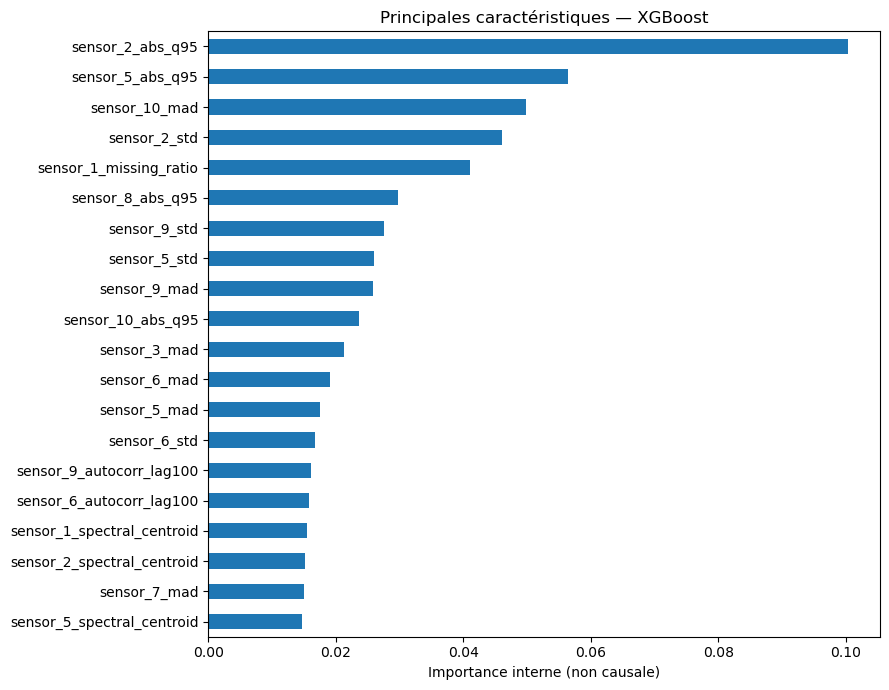

In [38]:
if hasattr(chosen, 'feature_importances_'):
    ranking = pd.Series(np.asarray(chosen.feature_importances_, dtype=float),
                        index=FEATURE_COLUMNS).sort_values(ascending=False)
    ranking.head(20).rename('importance').to_csv(OUT_DIR/'top_features.csv')
    fig, ax = plt.subplots(figsize=(9, 7))
    ranking.head(20).iloc[::-1].plot.barh(ax=ax)
    ax.set(title=f'Principales caractéristiques — {selected_name}',
           xlabel='Importance interne (non causale)', ylabel='')
    fig.tight_layout()
    fig.savefig(OUT_DIR/'importance_features.png', dpi=150)
    plt.show()
else:
    print('Baseline médiane retenue : aucune importance de caractéristiques.')

## 8 · Sauvegarder le modèle final pour réutilisation

Après avoir terminé l'évaluation, on peut réentraîner **le modèle choisi** sur l'ensemble des segments étiquetés afin de conserver un modèle réutilisable dans le projet. **Attention :** les performances du holdout présentées en section 7 concernent le modèle entraîné sur `X_dev`, et non celui réentraîné ci-dessous sur l'ensemble des données. Pour prédire un nouvel enregistrement, il faut d'abord appliquer la même extraction des 143 caractéristiques.

### 8.1 · Réentraîner et sauvegarder le modèle

In [39]:
final_model = clone(selected_template)
final_model.fit(X, y)

model_path = OUT_DIR / 'modele_final_INGV_143.joblib'
joblib.dump({
    'model': final_model,
    'feature_columns': FEATURE_COLUMNS,
    'feature_version': FEATURE_VERSION,
    'selected_model': selected_name,
    'random_state': SEED,
}, model_path, compress=3)

print('Modèle réentraîné sur', len(X), 'segments étiquetés')
print('Modèle sauvegardé :', model_path)

Modèle réentraîné sur 4431 segments étiquetés
Modèle sauvegardé : C:\Users\Alexis\Desktop\Projet INGV\outputs_INGV_143\modele_final_INGV_143.joblib
